# Data Preparation & Exploratory Data Analysis (EDA)

## 1. Business Understanding
**Goal:** Predict if an NHL team will change its head coach during the upcoming season.
**Why it matters:** For a General Manager (GM), knowing if a coach is at risk allows for proactive planning (scouting replacements, preparing a backup plan) and strategic decision-making.

## 2. Data Understanding & Preprocessing Strategy
In this notebook, we will clean the historical NHL data and engineer features that capture the context of a team **before** the season starts. 

**Crucial Methodology Note:** In a previous iteration of this project, we discovered a severe case of **Data Leakage** in the feature `coach_tenure`. The tenure was calculated using the current year's outcome, which artificially inflated our model's performance. This notebook presents the **corrected, leak-free version** of the data preparation.

In [1]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler

sns.set_theme(style="whitegrid")

# Load data
teams = pd.read_csv('./data/Teams.csv')
coaches = pd.read_csv('./data/Coaches.csv')
teamsHalf = pd.read_csv('./data/TeamsHalf.csv')
teamSplits = pd.read_csv('./data/TeamSplits.csv')
teamsPost = pd.read_csv('./data/TeamsPost.csv')
teamsSC = pd.read_csv('./data/TeamsSC.csv')
teamsVsTeam = pd.read_csv('./data/TeamVsTeam.csv')
scoring = pd.read_csv('./data/Scoring.csv')
master = pd.read_csv('./data/Master.csv')
abbrev = pd.read_csv('./data/abbrev.csv')
awardsCoaches = pd.read_csv('./data/AwardsCoaches.csv')
awardsPlayers = pd.read_csv('./data/AwardsPlayers.csv')
combinedShutouts = pd.read_csv('./data/CombinedShutouts.csv')
goalies = pd.read_csv('./data/Goalies.csv')
goaliesShootout = pd.read_csv('./data/GoaliesShootout.csv')
hof = pd.read_csv('./data/HOF.csv')
scoringShootout = pd.read_csv('./data/ScoringShootout.csv')
seriesPost = pd.read_csv('./data/SeriesPost.csv')

# Select Data

Based on the data analysis done in the data_analysis file, we remove all data prior to 1979.

In [2]:
YEAR = 1978

awardsCoaches       = awardsCoaches[awardsCoaches['year'] > YEAR]
awardsPlayers       = awardsPlayers[awardsPlayers['year'] > YEAR]
coaches = coaches[(coaches['year'] > YEAR) & (coaches['lgID'] == 'NHL')].copy()
combinedShutouts    = combinedShutouts[combinedShutouts['year'] > YEAR]
goalies             = goalies[goalies['year'] > YEAR]
goaliesShootout     = goaliesShootout[goaliesShootout['year'] > YEAR]
hof                 = hof[hof['year'] > YEAR]
scoring             = scoring[scoring['year'] > YEAR]
scoringShootout     = scoringShootout[scoringShootout['year'] > YEAR]
seriesPost          = seriesPost[seriesPost['year'] > YEAR]
teams = teams[(teams['year'] > YEAR) & (teams['lgID'] == 'NHL')].copy()
teamsHalf           = teamsHalf[teamsHalf['year'] > YEAR]
teamSplits          = teamSplits[teamSplits['year'] > YEAR]
teamsPost           = teamsPost[teamsPost['year'] > YEAR]
teamsSC             = teamsSC[teamsSC['year'] > YEAR]
teamsVsTeam         = teamsVsTeam[teamsVsTeam['year'] > YEAR]

# Keep only players whose last NHL season is 1979 or later
master              = master[master["lastNHL"] > YEAR]

# Clean Data

## Check which tables do not have data after 1978

If there are any tables that only contain older data, they are of no use to our predictions.

In [3]:
DATA_PATH = "data"

# Load every CSV once into a dict: {"teams": DataFrame, "goalies": DataFrame, ...}
tables = {}
for entry in sorted(os.scandir(DATA_PATH), key=lambda e: e.name):
    if entry.is_file() and entry.name.endswith(".csv"):
        name = os.path.splitext(entry.name)[0]
        tables[name] = pd.read_csv(entry.path)

empty_tables_post_1978 = []
for name, df in tables.items():
    # Check if there is a year column and then check if there is any data from 1979 onwards
    if "year" in df.columns:
        count = len(df[(df["year"]>=1979)])
        if count == 0:
            empty_tables_post_1978.append(name)

print(f"Deleting the following tables because they only have data before 1979: {empty_tables_post_1978}")

for table in empty_tables_post_1978:
    del tables[table]

Deleting the following tables because they only have data before 1979: ['GoaliesSC', 'ScoringSC', 'TeamsHalf', 'TeamsSC']


## Clean scoring for the PIMs prediction

Some of the scoring data needs cleanup before we can make any predictions

In [4]:
# Drop playoff-only rows (means only post-season games were played by that player that season)
scoring = scoring.dropna(subset=["GP"])
# Fill PIM with NaNs with 0
scoring["PIM"] = scoring["PIM"].fillna(0.0)
# Some players have multiple positions (eg. C/L). Keep the first position.
scoring["pos"] = scoring["pos"].str.split("/").str[0]

# Construct Data

Add a column for teams which have just changed coach (1 if so, 0 else)

## 3. Constructing the Target Variable
We define a 'coach change' (target = 1) if a franchise had more than one coach stint during a single season. This is derived from the `stint` column in the Coaches table.

In [5]:
# Coaches of the NHL teams only
teams = teams[teams["lgID"] == "NHL"].copy()
coaches = coaches[coaches["lgID"] == "NHL"].copy()

# Associate each coach record with a franchise.
team_franchises = teams[["tmID", "year", "franchID"]].drop_duplicates()
coaches_f = coaches.merge(team_franchises, on=["tmID", "year"], how="left")

# A change occurred if a coach has a stint > 1 during the season
changes = coaches_f.groupby(["franchID", "year"])["stint"].max().reset_index()
changes["coach_changed"] = (changes["stint"] > 1).astype(int)
changes = changes[["franchID", "year", "coach_changed"]]

teams = teams.merge(changes, on=["franchID", "year"], how="left")
teams["coach_changed"] = teams["coach_changed"].fillna(0).astype(int)

### 3.1 Target Distribution Analysis
**Why is this important?** Before modeling, we must understand our target distribution. If the data is highly imbalanced (e.g., 80% no change, 20% change), a naive model predicting 'no change' all the time would have 80% accuracy but be completely useless. This justifies our choice to optimize for the **F1-Score** rather than Accuracy in the next notebook.

/var/folders/_1/rpty0h7d4n3_2m8lsp5094xh0000gn/T/ipykernel_39555/3252925370.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='coach_changed', data=teams, palette='Set2')


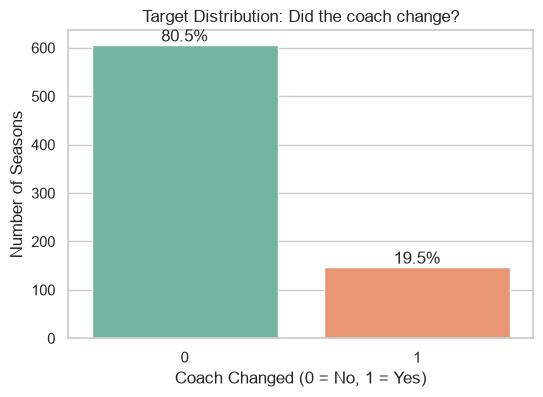

In [6]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(x='coach_changed', data=teams, palette='Set2')
plt.title('Target Distribution: Did the coach change?')
plt.xlabel('Coach Changed (0 = No, 1 = Yes)')
plt.ylabel('Number of Seasons')

total = len(teams)
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height/total:.1%}', (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom')
plt.show()

In [7]:
teams = teams.sort_values(['year', 'confID', 'Pts', 'tmID'],
                          ascending=[True, True, False, True]).copy()
teams['conference_rank'] = (
    teams.groupby(['year', 'confID']).cumcount() + 1
)
teams['conference_rank'] = teams['conference_rank'].astype(int)

teams = teams.sort_values(['tmID', 'year'])
teams['prev_conference_rank'] = teams.groupby('tmID')['conference_rank'].shift(1)

YEAR_TO_DISPLAY = 2008

print(f"Conference ranking for {YEAR_TO_DISPLAY}:")
print(
    teams[teams['year'] == YEAR_TO_DISPLAY]
    [['prev_conference_rank', 'conference_rank', 'confID', 'tmID', 'name', 'Pts']]
    .sort_values(['confID', 'conference_rank'])
    .to_string(index=False)
)

Conference ranking for 2008:
 prev_conference_rank  conference_rank confID tmID                  name  Pts
                  6.0                1     EC  BOS         Boston Bruins  116
                  8.0                2     EC  WAS   Washington Capitals  108
                  3.0                3     EC  NJD     New Jersey Devils  106
                  5.0                4     EC  PHI   Philadelphia Flyers   99
                  2.0                5     EC  PIT   Pittsburgh Penguins   99
                  9.0                6     EC  CAR   Carolina Hurricanes   97
                  4.0                7     EC  NYR      New York Rangers   95
                 11.0                8     EC  FLO      Florida Panthers   93
                  1.0                9     EC  MTL    Montreal Canadiens   93
                 10.0               10     EC  BUF        Buffalo Sabres   91
                  7.0               11     EC  OTT       Ottawa Senators   83
                 12.0              

## Features for coach-change prediction

These variables use only previous seasons, so the current season target is never used as an input.

In [8]:
teams = teams.sort_values(['franchID', 'year']).copy()
team_history = teams.groupby('franchID', sort=False)

# Changes in performance compared with the previous season.
teams['rank_change_1y'] = (
    team_history['rank'].shift(1) - team_history['rank'].shift(2)
)
teams['rank_change_2y'] = (
    team_history['rank'].shift(1) - team_history['rank'].shift(3)
)
teams['points_change_1y'] = (
    team_history['Pts'].shift(1) - team_history['Pts'].shift(2)
)
teams['goal_difference_1y'] = (
    team_history['GF'].shift(1) - team_history['GA'].shift(1)
)
teams['points_mean_3y'] = (
    team_history['Pts'].transform(
        lambda values: values.shift(1).rolling(3, min_periods=1).mean()
    )
)
teams['rank_mean_3y'] = (
    team_history['rank'].transform(
        lambda values: values.shift(1).rolling(3, min_periods=1).mean()
    )
)
teams['wins_mean_3y'] = (
    team_history['W'].transform(
        lambda values: values.shift(1).rolling(3, min_periods=1).mean()
    )
)

# Recent warning signals, all based on information available before the season.
teams['bad_recent_season'] = (
    team_history['rank'].shift(1) > 0.7
).astype('int8')
teams['strong_decline'] = (
    teams['rank_change_1y'] > 0.2
).astype('int8')
teams['previous_coach_change'] = (
    team_history['coach_changed'].shift(1)
).fillna(0).astype('int8')
teams['coach_changes_last_3y'] = (
    team_history['coach_changed']
    .transform(lambda values: values.shift(1).rolling(3, min_periods=1).sum())
).fillna(0).astype('int8')

teams = teams.sort_values(['year', 'tmID']).reset_index(drop=True)


## Features for the PIMs prediction

In [9]:
# If a player has several stints and positions in one year, keep the position with the highest games played
main_position = (
    scoring.sort_values("GP", ascending=False)
    .drop_duplicates(["playerID", "year"])
    .set_index(["playerID", "year"])["pos"]
)

player_seasons = (
    scoring.groupby(["playerID", "year"])
    .agg(PIM=("PIM", "sum"), GP=("GP", "sum"))
    .join(main_position)
    .reset_index()
)

# Add PIM per game column
player_seasons["PIM_per_game"] = player_seasons["PIM"] / player_seasons["GP"]

player_seasons["prev_year"] = player_seasons.groupby("playerID")["year"].shift(1)
player_seasons["prev_PIMs"] = player_seasons.groupby("playerID")["PIM"].shift(1)
player_seasons["prev_PIMs_per_game"] = player_seasons.groupby("playerID")["PIM_per_game"].shift(1)
# Players can be injured for a whole season, or have played in another league, so the previous year might 
# not be the calendar year. Adding this column in case this is relevant when calculating future PIMs
player_seasons["years_since_prev"] = player_seasons["year"] - player_seasons["prev_year"]
player_seasons["pos_group"] = player_seasons["pos"].map(
    {"C": "Forward", "L": "Forward", "R": "Forward", "D": "Defense", "G": "Goalie"}
)

**Finding:** When a player's previous year PIMs are NaN, it's because they were rookies or are in the 1979 cutoff year. We will need to predict PIMs for rookie players in a different way. Probably going for previous year PIMs per team and per position (which are known data points at the start of a rookie player's season).

# Integrate Data

For the PIM prediction, we need to add some information from the master table and from the team table to the players_season table so we can better predict PIM for players who are rookies and have no previous seasons.

In [10]:
#join master on playerID to add age (year - birthYear), height, weight

player_seasons = player_seasons.merge(
    master[["playerID", "birthYear"]].dropna(subset=["playerID"]),
    on="playerID",
    how="left",
)

player_seasons["player_age"] = player_seasons["year"] - player_seasons["birthYear"]

#join the team’s PIMs from the previous season by franchID
start_team = (
    scoring[scoring["stint"] == 1][["playerID", "year", "tmID"]]
    .drop_duplicates(["playerID", "year"])
)

# Mapping tmID with franchID
start_team = start_team.merge(
    teams[["tmID", "year", "franchID"]],
    on=["tmID", "year"],
    how="left",
)

# Team PIMs from the previous season, per franchise
pims_team_df = teams.sort_values(["franchID", "year"]).copy()
pims_team_df["team_prev_PIM"] = pims_team_df.groupby("franchID")["PIM"].shift(1)

# Attach to player_seasons
player_seasons = (
    player_seasons
    .merge(start_team[["playerID", "year", "franchID"]], on=["playerID", "year"], how="left")
    .merge(pims_team_df[["franchID", "year", "team_prev_PIM"]], on=["franchID", "year"], how="left")
)

# Format Data

Normalize the data

In [11]:
EXCLUDE_COLS = {
    'tmID', 'year', 'playerID', 'coachID', 'confID', 'divID',
    'lgID', 'teamID', 'franchID', 'pos', 'type', 'award',
    'coach_changed', 'PIM', 'PIM_per_game', 'pos_group'
}

def normalize_df(df):
    """Applies a MinMax scaling [0,1] on nums columns (except IDs)."""
    if df is None or df.empty:
        return df
    df = df.copy()
    numeric_cols = df.select_dtypes(include='number').columns
    cols_to_norm = [c for c in numeric_cols if c not in EXCLUDE_COLS]
    if cols_to_norm:
        scaler = MinMaxScaler()
        df[cols_to_norm] = scaler.fit_transform(df[cols_to_norm])
    return df

tables = {
    'abbrev':           abbrev,
    'awardsCoaches':    awardsCoaches,
    'awardsPlayers':    awardsPlayers,
    'coaches':          coaches,
    'combinedShutouts': combinedShutouts,
    'goalies':          goalies,
    'goaliesShootout':  goaliesShootout,
    'hof':              hof,
    'master':           master,
    'scoring':          scoring,
    'scoringShootout':  scoringShootout,
    'seriesPost':       seriesPost,
    'teams':            teams,
    'teamSplits':       teamSplits,
    'teamsPost':        teamsPost,
    'teamsVsTeam':      teamsVsTeam,
}

normalized_tables = {name: normalize_df(df) for name, df in tables.items()}

/opt/homebrew/Cellar/jupyterlab/4.6.4_2/libexec/lib/python3.15/site-packages/sklearn/utils/_array_api.py:899: RuntimeWarning: All-NaN slice encountered
  return xp.asarray(numpy.nanmin(X, axis=axis))
/opt/homebrew/Cellar/jupyterlab/4.6.4_2/libexec/lib/python3.15/site-packages/sklearn/utils/_array_api.py:919: RuntimeWarning: All-NaN slice encountered
  return xp.asarray(numpy.nanmax(X, axis=axis))
/opt/homebrew/Cellar/jupyterlab/4.6.4_2/libexec/lib/python3.15/site-packages/sklearn/utils/_array_api.py:899: RuntimeWarning: All-NaN slice encountered
  return xp.asarray(numpy.nanmin(X, axis=axis))
/opt/homebrew/Cellar/jupyterlab/4.6.4_2/libexec/lib/python3.15/site-packages/sklearn/utils/_array_api.py:919: RuntimeWarning: All-NaN slice encountered
  return xp.asarray(numpy.nanmax(X, axis=axis))
/opt/homebrew/Cellar/jupyterlab/4.6.4_2/libexec/lib/python3.15/site-packages/sklearn/utils/_array_api.py:899: RuntimeWarning: All-NaN slice encountered
  return xp.asarray(numpy.nanmin(X, axis=axis))


## 4. Feature Engineering (Leak-Free)
We create features based on past performance and coach history. 

**The Data Leakage Fix:** The `coach_tenure` feature is now calculated by looking **only at the past**. If a coach was changed last year, the new coach starts at tenure 1. If he stayed, the tenure increments. It no longer uses the current year's target.

In [12]:
teams = teams.sort_values(['franchID', 'year']).copy()
g = teams.groupby('franchID', sort=False)

# A. Previous season context
teams['prev_Pts'] = g['Pts'].shift(1)
teams['prev_rank'] = g['rank'].shift(1)
teams['prev_playoff'] = g['playoff'].shift(1).fillna('').ne('').astype(int)

# B. Deeper Performance Metrics (from Database Schema)
teams['prev_goal_diff'] = (g['GF'].shift(1) - g['GA'].shift(1)).fillna(0)
teams['prev_PP_pct'] = (g['PPG'].shift(1) / g['PPC'].shift(1)).fillna(0)
teams['prev_PK_pct'] = (1 - (g['PKG'].shift(1) / g['PKC'].shift(1))).fillna(0)

# C. Trends (Variations over 1 year)
teams['pts_change_1y'] = teams['prev_Pts'] - g['Pts'].shift(2)
teams['rank_change_1y'] = teams['prev_rank'] - g['rank'].shift(2)
teams['goal_diff_1y'] = teams['prev_goal_diff'] - (g['GF'].shift(2) - g['GA'].shift(2)).fillna(0)

# D. Coach History (Memory)
teams['prev_coach_changed'] = g['coach_changed'].shift(1).fillna(0)
teams['changes_last_3y'] = g['coach_changed'].transform(
    lambda s: s.shift(1).rolling(3, min_periods=1).sum()
).fillna(0)

# E. CORRECTED COACH TENURE (NO DATA LEAKAGE)
def calculate_tenure(group):
    tenure = []
    current_tenure = 0
    for changed in group['coach_changed'].shift(1): 
        if pd.isna(changed): 
            tenure.append(0)
            current_tenure = 0
            continue
        if changed == 1: 
            current_tenure = 1 # New coach starts his first season
        else: 
            current_tenure += 1 # Coach stayed, tenure increases
        tenure.append(current_tenure)
    return pd.Series(tenure, index=group.index)

teams['coach_tenure'] = teams.groupby('franchID', group_keys=False).apply(calculate_tenure)
teams = teams.sort_values(['year', 'tmID']).reset_index(drop=True)

## 5. Exploratory Data Analysis (EDA) on Features
Let's visualize the relationship between our newly engineered features and the target. This helps us understand if our features actually carry predictive signal.

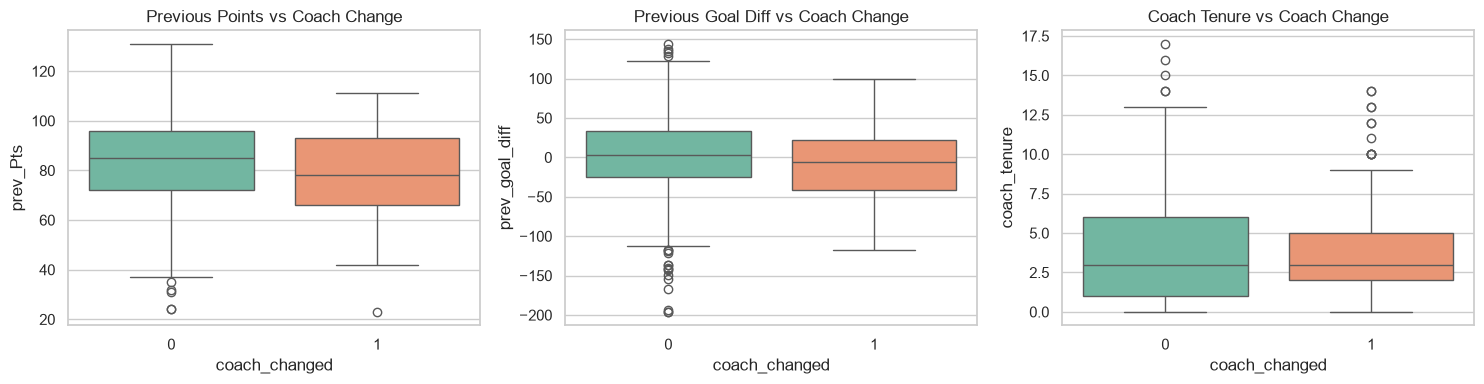

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.boxplot(x='coach_changed', y='prev_Pts', data=teams, ax=axes[0], palette='Set2', hue='coach_changed', legend=False)
axes[0].set_title('Previous Points vs Coach Change')

sns.boxplot(x='coach_changed', y='prev_goal_diff', data=teams, ax=axes[1], palette='Set2', hue='coach_changed', legend=False)
axes[1].set_title('Previous Goal Diff vs Coach Change')

sns.boxplot(x='coach_changed', y='coach_tenure', data=teams, ax=axes[2], palette='Set2', hue='coach_changed', legend=False)
axes[2].set_title('Coach Tenure vs Coach Change')

plt.tight_layout()
plt.show()

**Interpretation of Boxplots:**
- **Previous Points & Goal Diff:** Teams that change coaches tend to have slightly lower medians in previous points and goal differentials. The signal is there, but weak.
- **Coach Tenure:** The boxplot shows that coaches with shorter tenures (e.g., 1 or 2 years) are more likely to be fired. This makes sense: a new coach is often on a 'probation period', and if results don't come quickly, they are dismissed. However, since we fixed the data leakage, this feature no longer perfectly separates the classes.

## 6. Data Quality & Correlation Analysis
### 6.1 Missing Values & Imputation
We have missing values because the first year of any franchise has no 'previous season'. We use **median imputation** to handle them without losing valuable historical rows. The plot below compares the missing values before and after imputation.

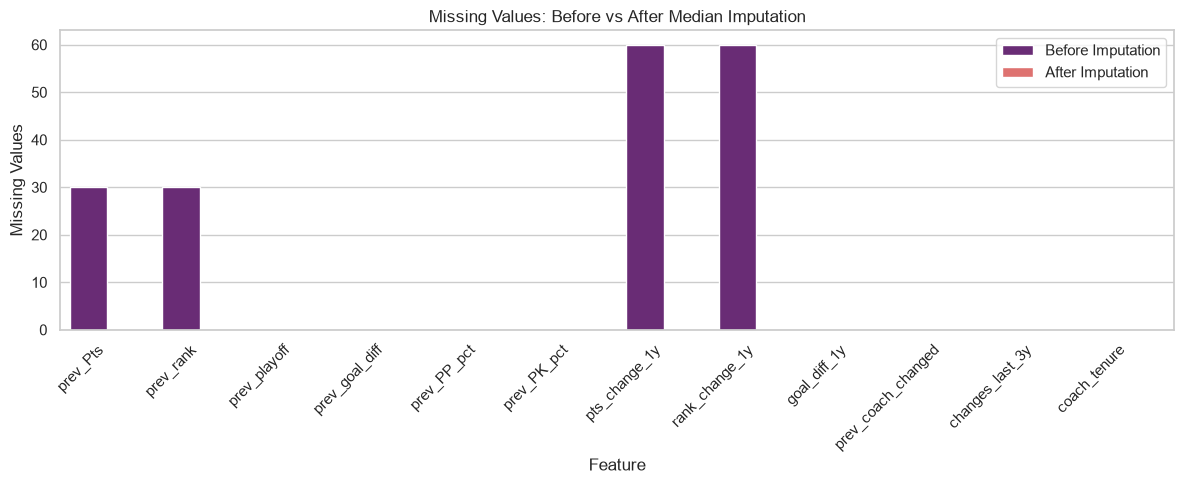

Missing values after imputation: 0


In [14]:
features = [
    'prev_Pts', 'prev_rank', 'prev_playoff', 'prev_goal_diff', 'prev_PP_pct', 'prev_PK_pct',
    'pts_change_1y', 'rank_change_1y', 'goal_diff_1y',
    'prev_coach_changed', 'changes_last_3y', 'coach_tenure'
]

# Data for the plot
missing_before = teams[features].isna().sum()
teams[features] = teams[features].fillna(teams[features].median())
missing_after = teams[features].isna().sum()

df_missing = pd.DataFrame({'Before Imputation': missing_before, 'After Imputation': missing_after})
df_missing = df_missing.reset_index().melt(id_vars='index', var_name='State', value_name='Missing Values')
df_missing.rename(columns={'index': 'Feature'}, inplace=True)

plt.figure(figsize=(12, 5))
sns.barplot(data=df_missing, x='Feature', y='Missing Values', hue='State', palette='magma')
plt.title('Missing Values: Before vs After Median Imputation')
plt.xticks(rotation=45, ha='right')
plt.legend()
plt.tight_layout()
plt.show()

print("Missing values after imputation:", teams[features].isna().sum().sum())

### 6.2 Correlation Matrix
**Why this matters:** We want to avoid **multicollinearity** (features that are too highly correlated with each other), as it can confuse linear models like Logistic Regression. If two features are 0.99 correlated, we only need one. Here, the features are mostly independent, which is excellent.

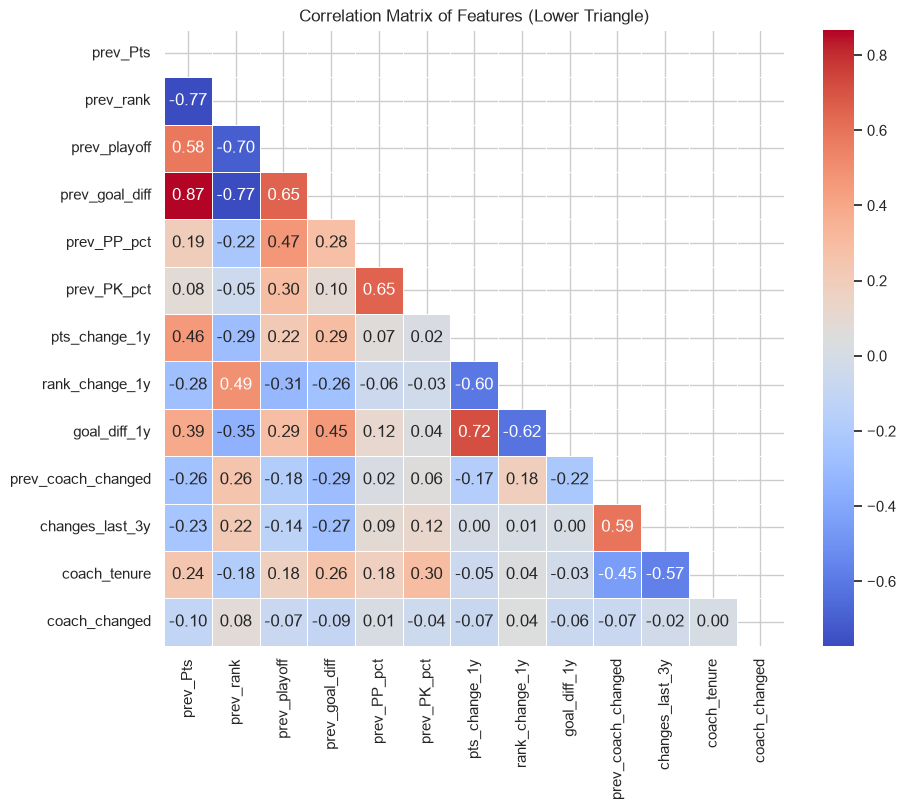

In [15]:
plt.figure(figsize=(10, 8))
corr_matrix = teams[features + ['coach_changed']].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(corr_matrix, mask=mask, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Features (Lower Triangle)')
plt.show()

## 7. Final Scaling & Saving
Finally, we apply `MinMaxScaler` so that algorithms sensitive to scale (like SVM or Logistic Regression) are not biased by variables with large magnitudes (like Points, which is in the 80-100 range). The plot below shows the impact of the scaling on a sample feature.

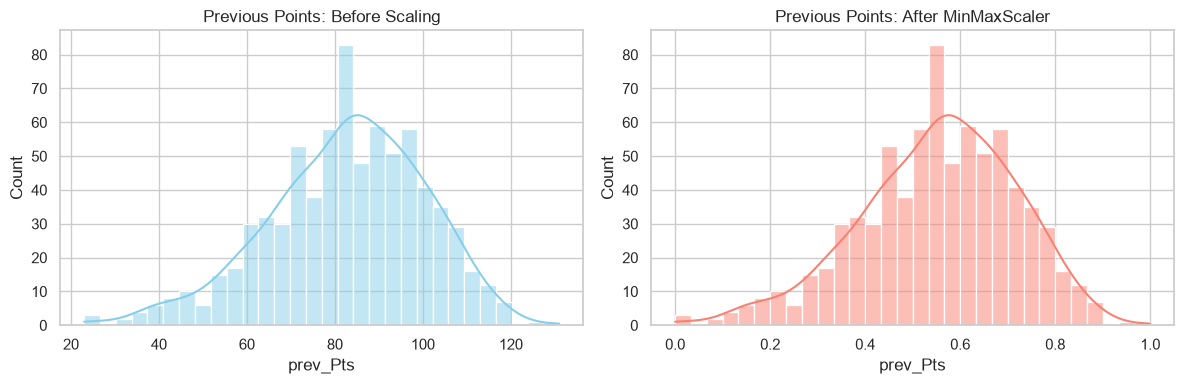

File saved: ./data_prepared/teams_final.csv with 753 rows.


In [16]:
# Store a copy before scaling for the plot
teams_unscaled = teams[features].copy()

# Apply scaling
scaler = MinMaxScaler()
teams[features] = scaler.fit_transform(teams[features])

# Create the plot
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(teams_unscaled['prev_Pts'], bins=30, ax=axes[0], color='skyblue', kde=True)
axes[0].set_title('Previous Points: Before Scaling')
sns.histplot(teams['prev_Pts'], bins=30, ax=axes[1], color='salmon', kde=True)
axes[1].set_title('Previous Points: After MinMaxScaler')
plt.tight_layout()
plt.show()

# Save
cols_to_keep = ['franchID', 'year', 'coach_changed'] + features
teams_clean = teams[cols_to_keep].copy()

os.makedirs('./data_prepared', exist_ok=True)
teams_clean.to_csv('./data_prepared/teams_final.csv', index=False)
print(f"File saved: ./data_prepared/teams_final.csv with {len(teams_clean)} rows.")

### Add the player_seasons new table into data_prepared

In [17]:
os.makedirs('./data_prepared', exist_ok=True)
player_seasons.to_csv('./data_prepared/player_seasons.csv', index=False)
print(f"File saved: ./data_prepared/player_seasons.csv with {len(player_seasons)} rows.")

File saved: ./data_prepared/player_seasons.csv with 24612 rows.
